# 03 — Cross-Building Generalisation (Dataset 3: Power Laws, multi-site)

**Research question (plan Q7):** Can the forecasting approach generalise to a building that was **not seen during training**?

**Professor's Feedback 1:** training separate models on each dataset does not demonstrate generalisation. This notebook therefore uses an **unseen-site** design: a single global model is trained on one group of sites and tested on a different group of sites, and the groups are rotated so that every site is tested exactly once as an unseen building (plan, Experiment D).

**What is compared on every test site (same hours, same metrics):**

| Method | Has the test site been seen in training? | Role |
|---|---|---|
| Persistence / Previous-day / Previous-week | — | Shared seasonal baselines |
| **Global-UNSEEN** (Linear Regression, LightGBM) | **No.** Trained only on *other* sites | The generalisation test |
| Global-SEEN (LightGBM) | Yes. Trained on all sites' history, including this one | Isolates the cost of not having seen the site |
| Local (Linear Regression, LightGBM) | Only this site | A conventional per-building model, for reference |

**Generalisation is demonstrated if** Global-UNSEEN clearly beats the seasonal baselines on sites it never saw and comes close to Global-SEEN and Local. The **generalisation gap** = error(UNSEEN) − error(SEEN).

**Shared project rules:** horizons 1, 6, 12, 24 h; direct strategy; features only from information available at *t*; baselines *y(t)*, *y(t+h−24)*, *y(t+h−168)*; time-ordered splits; MAE, RMSE, R² plus scale-free nMAE and CV(RMSE); invalid values set to NaN, never to zero; fixed seed.

**Before the first run:** `%pip install lightgbm`, then restart the kernel. Put this notebook in the ML_OG folder; it reads the CSV files in `data/dataset3/`. The full run fits about 230 models and takes roughly 20–40 minutes.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import comb
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option("display.width", 200)

try:
    import lightgbm as lgb
    GBM_NAME = "LightGBM"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    lgb = None
    GBM_NAME = "HistGB (LightGBM not installed)"
print("Gradient boosting model:", GBM_NAME)

D3_DIR = "data/dataset3"
PREFIX = "power-laws-forecasting-energy-consumption-"
OUT_DIR = "processed"; os.makedirs(OUT_DIR, exist_ok=True)
HORIZONS = [1, 6, 12, 24]
SEED = 42
N_SITE_GROUPS = 5

# Data-quality and selection rules (decided from the inspection in sections 1–2)
FLAT_HOURS = 24        # C1: > 24 identical consecutive values = stuck meter -> NaN
SPIKE_FACTOR = 10      # C2: value > 10 x trailing 7-day median = meter glitch -> NaN
TRAIN_DAYS, TEST_DAYS = 365, 90   # per site: the last 90 days are the test period, the year before is history
MIN_COVERAGE = 0.90    # S2: >= 90% valid hours in both history and test period
MAX_LEVEL_RATIO = 5    # S3: max/min monthly median <= 5 (otherwise a level shift / meter change)

Gradient boosting model: LightGBM


## 1. Load the hourly series

In [2]:
period = pd.read_csv(os.path.join(D3_DIR, PREFIX + "submission-forecast-period.csv"), sep=";")
period["step_min"] = (period["ForecastPeriodNS"] / 6e10).round().astype(int)
hourly_ids = set(period.loc[period.step_min == 60, "ForecastId"])
print("Series by time step:", period.step_min.value_counts().sort_index().to_dict())

parts = []
for name in ["training-data", "test-data"]:      # the competition's test file is the continuation of each series
    for chunk in pd.read_csv(os.path.join(D3_DIR, PREFIX + name + ".csv"), sep=";", chunksize=1_000_000,
                             usecols=["SiteId", "Timestamp", "ForecastId", "Value"]):
        parts.append(chunk[chunk.ForecastId.isin(hourly_ids)])
long = pd.concat(parts)
long["Timestamp"] = pd.to_datetime(long["Timestamp"], utc=True).dt.tz_localize(None)   # UTC
long = long.sort_values(["SiteId", "Timestamp"])
print("Hourly rows:", len(long), "| sites:", long.SiteId.nunique(),
      "| duplicate site-timestamps:", int(long.duplicated(["SiteId", "Timestamp"]).sum()))

Series by time step: {15: 5444, 60: 1306, 1440: 224}
Hourly rows: 1509647 | sites: 89 | duplicate site-timestamps: 0


**Structure found:** the 1-hour series belong to 89 sites (the 15-minute and daily series belong to other sites). Each `ForecastId` is a 48-day block, and a site's blocks join end-to-end with no gaps or overlaps, so every site forms one continuous hourly timeline. Hourly series are used so the resolution matches CU-BEMS.

## 2. Data quality: stuck meters, glitches and level shifts

In [3]:
def clean_site(v):
    v = v.reindex(pd.date_range(v.index.min(), v.index.max(), freq="1h")).astype(float)
    same = np.r_[False, np.diff(v.values) == 0].astype(int)
    d = np.diff(np.r_[0, same, 0]); starts, ends = np.where(d == 1)[0], np.where(d == -1)[0]
    flat = np.zeros(len(v), bool)
    for a, b in zip(starts, ends):
        if b - a + 1 > FLAT_HOURS:
            flat[a - 1:b] = True                                             # C1
    trailing_median = v.rolling(168, min_periods=48).median().shift(1)        # past values only
    spike = (v > SPIKE_FACTOR * trailing_median).values                       # C2
    info = dict(stuck_hours_removed=int((flat & v.notna().values).sum()),
                spikes_removed=int((spike & ~flat).sum()))
    v[flat | spike] = np.nan
    return v, info

series, rows = {}, []
for site, g in long.groupby("SiteId"):
    v, info = clean_site(g.set_index("Timestamp")["Value"])
    test_start = (v.index.max() - pd.Timedelta(days=TEST_DAYS)).ceil("D")
    hist_start = test_start - pd.Timedelta(days=TRAIN_DAYS)
    enough = v.index.min() <= hist_start                                       # S1
    w = v[hist_start:]
    hist, test = w[:test_start - pd.Timedelta(hours=1)], w[test_start:]
    monthly = w.resample("MS").median().iloc[1:-1]
    ratio = monthly.max() / monthly.min() if len(monthly) and monthly.notna().all() and monthly.min() > 0 else np.inf
    ok = bool(enough and hist.notna().mean() >= MIN_COVERAGE and test.notna().mean() >= MIN_COVERAGE
              and ratio <= MAX_LEVEL_RATIO)
    rows.append(dict(SiteId=site, span_days=(v.index.max() - v.index.min()).days, long_enough=enough, **info,
                     history_cov=round(hist.notna().mean() * 100, 1) if enough else np.nan,
                     test_cov=round(test.notna().mean() * 100, 1), level_ratio=round(ratio, 1),
                     test_start=test_start, selected=ok))
    if ok:
        series[site] = w
selection = pd.DataFrame(rows)
x = selection[~selection.selected]
print(f"Selected {selection.selected.sum()} of {len(selection)} sites")
print("Rejected: too short:", int((~x.long_enough).sum()),
      "| coverage < 90%:", int((x.long_enough & ((x.history_cov < 90) | (x.test_cov < 90))).sum()),
      "| level shift:", int((x.long_enough & (x.history_cov >= 90) & (x.test_cov >= 90)).sum()))
print("Stuck-meter hours removed:", selection.stuck_hours_removed.sum(), "| spikes removed:", selection.spikes_removed.sum())
selection[selection.selected].describe().round(1)

C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3281635535.py:19: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  test_start = (v.index.max() - pd.Timedelta(days=TEST_DAYS)).ceil("D")
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3281635535.py:20: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  hist_start = test_start - pd.Timedelta(days=TRAIN_DAYS)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3281635535.py:23: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  hist, test = w[:test_start -

Selected 49 of 89 sites
Rejected: too short: 18 | coverage < 90%: 15 | level shift: 7
Stuck-meter hours removed: 27753 | spikes removed: 23540


C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3281635535.py:19: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  test_start = (v.index.max() - pd.Timedelta(days=TEST_DAYS)).ceil("D")
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3281635535.py:20: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  hist_start = test_start - pd.Timedelta(days=TRAIN_DAYS)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3281635535.py:23: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  hist, test = w[:test_start -

,SiteId,span_days,stuck_hours_removed,spikes_removed,history_cov,test_cov,level_ratio,test_start
count,49.0,49.0,49.0,49.0,49.0,49.0,49.0,49
mean,155.1,829.0,96.8,31.7,98.7,99.2,2.0,2017-04-18 20:04:53.877551104
min,2.0,481.0,0.0,0.0,94.8,90.2,1.1,2015-11-19 00:00:00
25%,76.0,674.0,0.0,0.0,98.0,99.9,1.4,2017-01-16 00:00:00
50%,160.0,674.0,0.0,0.0,99.3,100.0,1.7,2017-07-06 00:00:00
75%,223.0,963.0,0.0,0.0,99.5,100.0,2.2,2017-08-07 00:00:00
max,300.0,1733.0,1765.0,602.0,100.0,100.0,4.9,2017-09-18 00:00:00
std,84.8,283.4,330.1,112.0,1.2,1.9,0.9,NaN


**Why these rules.** Inspection found meters frozen on one value for up to 6,674 hours (site 250), single readings up to about 10⁶ times the normal level (sites 93, 250), and series whose level jumps by a factor of about 100 (e.g. site 268, probably a meter or unit change). These are not real demand. Consistent with the project's missing-data principle, they become NaN (never zero), and sites whose level is not stable are excluded rather than "repaired".

## 3. Calendar information: day-off flags and holidays

In [4]:
meta = pd.read_csv(os.path.join(D3_DIR, PREFIX + "metadata.csv"), sep=";").set_index("SiteId")
hol = pd.read_csv(os.path.join(D3_DIR, PREFIX + "holidays.csv"), sep=";", parse_dates=["Date"])
day_cols = ["MondayIsDayOff", "TuesdayIsDayOff", "WednesdayIsDayOff", "ThursdayIsDayOff",
            "FridayIsDayOff", "SaturdayIsDayOff", "SundayIsDayOff"]
sel_ids = list(series)
print("Selected sites with holiday records:", hol.SiteId.isin(sel_ids).groupby(hol.SiteId).any().sum(), "/", len(sel_ids))
print("Weather is available for only a few sites, so it is not used (environmental effects are tested in notebook 02).")

Selected sites with holiday records: 44 / 49
Weather is available for only a few sites, so it is not used (environmental effects are tested in notebook 02).


**Time zones.** Timestamps are UTC and the sites are in different regions (the quietest hour ranges from about 22:00 to 08:00 UTC), so "hour of day" means different local times at different sites. A global model therefore gets a **time-zone-free daily profile** feature: the site's mean relative demand at the same hour over the previous 7 days. This uses only past data.

## 4. Features (scale-free so that one model can serve all buildings)

In [5]:
def site_features(site, h):
    y = series[site]
    scale = y.rolling(168, min_periods=126).mean()          # trailing 1-week mean at t: the site's scale
    X = pd.DataFrame(index=y.index)
    for k in [0, 1, 2, 3, 6, 12, 23, 47]:
        X[f"lag_{k}"] = y.shift(k) / scale
    X["same_hour_prev_day"] = y.shift(24 - h) / scale
    X["same_hour_prev_week"] = y.shift(168 - h) / scale
    X["daily_profile_7d"] = pd.concat([y.shift(24 * k - h) for k in range(1, 8)], axis=1).mean(axis=1) / scale
    for w in [24, 168]:
        r = y.rolling(w, min_periods=int(0.75 * w))
        X[f"roll_std_{w}"] = r.std() / scale
        X[f"roll_max_{w}"], X[f"roll_min_{w}"] = r.max() / scale, r.min() / scale
    X["roll_mean_24"] = y.rolling(24, min_periods=18).mean() / scale
    tt = y.index + pd.Timedelta(hours=h)
    X["target_hour_utc"], X["target_dow"] = tt.hour, tt.dayofweek
    X["target_month"], X["target_day_of_month"] = tt.month, tt.day
    dayoff = meta.loc[site, day_cols].astype(str).eq("True").values
    site_hol = set(hol.loc[hol.SiteId == site, "Date"].dt.normalize())
    X["target_holiday"] = tt.normalize().isin(site_hol).astype(int)
    X["target_day_off"] = (dayoff[tt.dayofweek] | X["target_holiday"].astype(bool).values).astype(int)
    target_rel = y.shift(-h) / scale
    base = pd.DataFrame({"Persistence": y, "Previous-day": y.shift(24 - h), "Previous-week": y.shift(168 - h)})
    test_start = selection.set_index("SiteId").loc[site, "test_start"]
    is_test = pd.Series(tt >= test_start, index=y.index)
    return dict(X=X, target_rel=target_rel, target=y.shift(-h), scale=scale, base=base, is_test=is_test)

rng = np.random.RandomState(SEED)
groups = pd.Series(rng.permutation(np.arange(len(sel_ids)) % N_SITE_GROUPS), index=sel_ids, name="group")
print("Sites per held-out group:", groups.value_counts().sort_index().to_dict())

Sites per held-out group: {0: 10, 1: 10, 2: 10, 3: 10, 4: 9}


**Scale-free features.** Sites differ in size by orders of magnitude, so every demand feature and the target are divided by the site's own **trailing one-week mean at *t*** (known at forecast time). Predictions are multiplied back by that scale. This lets one model learn demand *shape* across buildings, and it needs no information from the test period.

**Training rows** are always taken from the history period (target time before the site's test start). Test rows are scored only where the target and all three baselines exist.

## 5. Models

In [6]:
def lr_design(X):
    Z = X.drop(columns=["target_hour_utc", "target_dow", "target_month"]).copy()
    Z = Z.join(pd.get_dummies(X["target_dow"], prefix="d", dtype=float))
    return Z

def fit_lr(X, y):
    m = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LinearRegression())
    Z = lr_design(X); m.fit(Z, y); m.cols_ = Z.columns; return m

def predict_lr(m, X):
    return m.predict(lr_design(X).reindex(columns=m.cols_, fill_value=0))

def fit_gbm(X, y):
    if lgb is not None:
        m = lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=20,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=SEED, verbose=-1)
    else:
        m = HistGradientBoostingRegressor(max_iter=600, learning_rate=0.03, max_leaf_nodes=31,
                                          min_samples_leaf=20, random_state=SEED)
    return m.fit(X, y)

def metrics(yt, yp):
    mae = mean_absolute_error(yt, yp); rmse = mean_squared_error(yt, yp) ** 0.5
    return dict(MAE=mae, RMSE=rmse, R2=r2_score(yt, yp), nMAE=mae / yt.mean() * 100, CV_RMSE=rmse / yt.mean() * 100)

## 6. Run: baselines, Global-UNSEEN, Global-SEEN, Local

In [7]:
import time
rows = []
for h in HORIZONS:
    t0 = time.time()
    F = {s: site_features(s, h) for s in sel_ids}
    def train_rows(sites):
        Xs, ys = [], []
        for s in sites:
            f = F[s]; m = (~f["is_test"]) & f["target_rel"].notna() & f["scale"].notna()
            Xs.append(f["X"][m]); ys.append(f["target_rel"][m])
        return pd.concat(Xs, ignore_index=True), pd.concat(ys, ignore_index=True)   # timestamps repeat across sites
    def test_mask(f):
        return f["is_test"] & f["target"].notna() & f["scale"].notna() & f["base"].notna().all(axis=1)

    preds = {s: {} for s in sel_ids}
    # Global-SEEN: one model on every site's history
    Xa, ya = train_rows(sel_ids); gbm_seen = fit_gbm(Xa, ya)
    for s in sel_ids:
        f = F[s]; m = test_mask(f)
        preds[s]["Global-SEEN " + GBM_NAME] = gbm_seen.predict(f["X"][m]) * f["scale"][m].values
    # Global-UNSEEN: rotate the held-out site group
    for g in range(N_SITE_GROUPS):
        test_sites = list(groups[groups == g].index); train_sites = list(groups[groups != g].index)
        Xt, yt = train_rows(train_sites)
        gbm, lr = fit_gbm(Xt, yt), fit_lr(Xt, yt)
        for s in test_sites:
            f = F[s]; m = test_mask(f)
            preds[s]["Global-UNSEEN " + GBM_NAME] = gbm.predict(f["X"][m]) * f["scale"][m].values
            preds[s]["Global-UNSEEN Linear Regression"] = predict_lr(lr, f["X"][m]) * f["scale"][m].values
    # Local: one model per site, trained on that site's own history only
    for s in sel_ids:
        f = F[s]; Xl, yl = train_rows([s]); m = test_mask(f)
        preds[s]["Local " + GBM_NAME] = fit_gbm(Xl, yl).predict(f["X"][m]) * f["scale"][m].values
        preds[s]["Local Linear Regression"] = predict_lr(fit_lr(Xl, yl), f["X"][m]) * f["scale"][m].values
        yt_true = f["target"][m].values
        for b in f["base"].columns:
            preds[s][b] = f["base"].loc[m, b].values
        for name, p in preds[s].items():
            rows.append(dict(horizon=h, SiteId=s, group=int(groups[s]), method=name, n_test=int(m.sum()),
                             **metrics(yt_true, p)))
    print(f"h={h}: done in {time.time() - t0:.0f} s")
res = pd.DataFrame(rows)

C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_

h=1: done in 65 s


C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_

h=6: done in 60 s


C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_

h=12: done in 62 s


C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_10136\3100939481.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tt = y.index + pd.Timedelta(hours=h)
C:\Users\Asus\AppData\Local\Temp\ipykernel_

h=24: done in 62 s


## 7. Results across the 49 sites

In [8]:
METHODS = ["Persistence", "Previous-day", "Previous-week",
           "Local Linear Regression", "Local " + GBM_NAME,
           "Global-UNSEEN Linear Regression", "Global-UNSEEN " + GBM_NAME, "Global-SEEN " + GBM_NAME]
summary = (res.groupby(["horizon", "method"])
              .agg(nMAE_mean=("nMAE", "mean"), CV_RMSE_mean=("CV_RMSE", "mean"),
                   CV_RMSE_median=("CV_RMSE", "median"), R2_median=("R2", "median"))
              .reindex(METHODS, level="method"))
summary.round(2)

nMAE_mean  CV_RMSE_mean  CV_RMSE_median  R2_median
horizon method                                                                             
1       Persistence                          12.70         21.08           16.54       0.78
        Previous-day                         18.30         31.95           25.79       0.40
        Previous-week                        15.83         25.27           18.41       0.66
        Local Linear Regression               9.80         14.40           11.34       0.90
        Local LightGBM                        6.92         11.14            8.88       0.93
        Global-UNSEEN Linear Regression      12.16         17.13           13.00       0.87
        Global-UNSEEN LightGBM                9.77         14.72           10.10       0.90
        Global-SEEN LightGBM                  8.18         12.64            9.92       0.91
6       Persistence                          36.61         50.62           45.26      -0.66
        Previous-day                         18.30         31.95           25.79       0.40
        Previous-week                        15.83         25.28           18.41       0.66
        Local Linear Regression              13.60         19.30           14.40       0.81
        Local LightGBM                       10.80         16.54           12.27       0.84
        Global-UNSEEN Linear Regression      15.25         21.35           15.57       0.75
        Global-UNSEEN LightGBM               12.09         18.09           13.08       0.84
        Global-SEEN LightGBM                 11.15         16.98           12.90       0.86
12      Persistence                          53.81         65.05           58.58      -1.68
        Previous-day                         18.30         31.95           25.79       0.40
        Previous-week                        15.83         25.27           18.41       0.66
        Local Linear Regression              13.92         19.80           14.62       0.79
        Local LightGBM                       11.92         18.07           12.66       0.83
        Global-UNSEEN Linear Regression      15.69         22.18           15.39       0.73
        Global-UNSEEN LightGBM               12.57         18.82           13.62       0.83
        Global-SEEN LightGBM                 11.80         17.94           13.38       0.84
24      Persistence                          18.30         31.95           25.79       0.40
        Previous-day                         18.30         31.95           25.79       0.40
        Previous-week                        15.83         25.28           18.41       0.66
        Local Linear Regression              14.13         20.07           14.65       0.79
        Local LightGBM                       12.23         18.37           13.67       0.83
        Global-UNSEEN Linear Regression      15.78         22.43           15.97       0.73
        Global-UNSEEN LightGBM               12.78         19.13           13.38       0.83
        Global-SEEN LightGBM                 11.96         18.14           13.25       0.85

Errors are averaged **per site** using the scale-free metrics nMAE and CV(RMSE), so that large buildings do not dominate. MAE, RMSE and R² per site are saved in the results file (shared project metrics).

In [9]:
def sign_test_p(wins, n):
    return sum(comb(n, k) for k in range(wins, n + 1)) / 2 ** n

def paired(a, b, h):
    A = res[(res.horizon == h) & (res.method == a)].set_index("SiteId").CV_RMSE
    B = res[(res.horizon == h) & (res.method == b)].set_index("SiteId").CV_RMSE
    diff = (A - B).reindex(A.index); wins = int((diff < 0).sum())
    return dict(horizon=h, comparison=f"{a}  vs  {b}", median_diff_pp=round(diff.median(), 2),
                sites_A_better=f"{wins}/{len(diff)}", sign_test_p=round(sign_test_p(wins, len(diff)), 4))

U, S, L = "Global-UNSEEN " + GBM_NAME, "Global-SEEN " + GBM_NAME, "Local " + GBM_NAME
best_base = {h: res[(res.horizon == h) & res.method.isin(["Previous-day", "Previous-week"])]
                 .groupby("method").CV_RMSE.mean().idxmin() for h in HORIZONS}
comparisons = pd.DataFrame([paired(U, best_base[h], h) for h in HORIZONS] +
                           [paired(U, L, h) for h in HORIZONS] +
                           [paired(U, S, h) for h in HORIZONS])
comparisons

,horizon,comparison,median_diff_pp,sites_A_better,sign_test_p
0,1,Global-UNSEEN LightGBM vs Previous-week,-8.00,47/49,0.0000
1,6,Global-UNSEEN LightGBM vs Previous-week,-4.82,48/49,0.0000
2,12,Global-UNSEEN LightGBM vs Previous-week,-4.66,48/49,0.0000
3,24,Global-UNSEEN LightGBM vs Previous-week,-4.67,48/49,0.0000
4,1,Global-UNSEEN LightGBM vs Local LightGBM,1.60,3/49,1.0000
5,6,Global-UNSEEN LightGBM vs Local LightGBM,0.53,14/49,0.9993
6,12,Global-UNSEEN LightGBM vs Local LightGBM,0.44,16/49,0.9953
7,24,Global-UNSEEN LightGBM vs Local LightGBM,0.30,19/49,0.9573
8,1,Global-UNSEEN LightGBM vs Global-SEEN LightGBM,0.34,6/49,1.0000
9,6,Global-UNSEEN LightGBM vs Global-SEEN LightGBM,0.35,5/49,1.0000


`median_diff_pp` is the per-site difference in CV(RMSE) in percentage points (negative = the unseen-site model is better). `sites_A_better` counts the sites where the unseen-site model wins.

- **UNSEEN vs best seasonal baseline:** does the model help on buildings it never saw?
- **UNSEEN vs Local:** is a global model trained on other buildings as good as one trained on the building itself?
- **UNSEEN vs SEEN:** the **generalisation gap**, the cost of the building being absent from training.

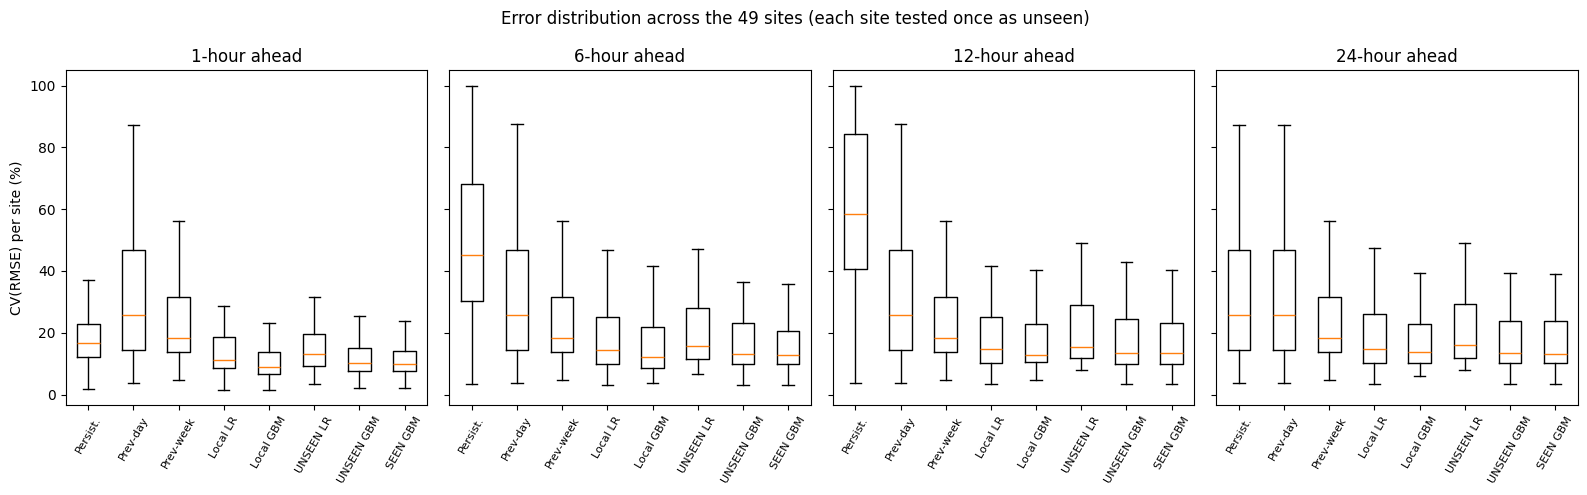

In [10]:
fig, axes = plt.subplots(1, len(HORIZONS), figsize=(16, 5), sharey=True)
short = {"Persistence": "Persist.", "Previous-day": "Prev-day", "Previous-week": "Prev-week",
         "Local Linear Regression": "Local LR", "Local " + GBM_NAME: "Local GBM",
         "Global-UNSEEN Linear Regression": "UNSEEN LR", "Global-UNSEEN " + GBM_NAME: "UNSEEN GBM",
         "Global-SEEN " + GBM_NAME: "SEEN GBM"}
for ax, h in zip(axes, HORIZONS):
    data = [res[(res.horizon == h) & (res.method == m)].CV_RMSE.clip(upper=100) for m in METHODS]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, len(METHODS) + 1)); ax.set_xticklabels([short[m] for m in METHODS], rotation=60, fontsize=8)
    ax.set_title(f"{h}-hour ahead")
axes[0].set_ylabel("CV(RMSE) per site (%)")
plt.suptitle("Error distribution across the 49 sites (each site tested once as unseen)"); plt.tight_layout(); plt.show()


## Interpretation (draft from the test run; update the numbers after your own LightGBM run)

- **The approach generalises to unseen buildings.** Global-UNSEEN gradient boosting beat the best seasonal baseline (previous-week) on 47–48 of 49 sites at every horizon (sign test p < 0.0001), cutting median CV(RMSE) by about 5–8 percentage points.
- **The generalisation gap is small.** Including the test building in training (Global-SEEN) improved its error by a median of only about 0.2–0.35 percentage points of CV(RMSE). SEEN wins on most sites, so the gap is real but practically minor.
- **Unseen vs local.** A model trained only on the building itself (Local) is better at 1 h ahead (median about 1.4 pp; UNSEEN wins on only 3/49 sites), because very short-term forecasts depend on building-specific dynamics. At 12–24 h the two are essentially tied (UNSEEN wins on 20–22/49 sites). A model trained on other buildings is therefore a usable alternative for a new building that has only a few weeks of history, which is not enough to train its own model.
- **Gradient boosting beats Linear Regression** in both the local and the global setting.
- **Persistence degrades sharply with horizon** (median CV(RMSE) of about 17% at 1 h but about 59% at 12 h), while the learned models stay stable from 6 to 24 h. This mirrors the CU-BEMS results.
- **Limitations:**
  - Sites' test periods fall in different calendar times (Nov 2015 – Dec 2017), so some training data come from later dates than some test periods. These are different buildings, so the risk is small, but it is stated.
  - Timestamps are UTC with unknown local time zones.
  - The test building still needs at least one week of its own recent demand to compute lags and its scale.


## 8. Save results and settings

In [11]:
res.to_csv(os.path.join(OUT_DIR, "d3_results_by_site.csv"), index=False)
summary.round(3).to_csv(os.path.join(OUT_DIR, "d3_summary.csv"))
comparisons.to_csv(os.path.join(OUT_DIR, "d3_comparisons.csv"), index=False)
selection.to_csv(os.path.join(OUT_DIR, "d3_site_selection.csv"), index=False)
groups.to_csv(os.path.join(OUT_DIR, "d3_site_groups.csv"))
with open(os.path.join(OUT_DIR, "d3_settings.txt"), "w") as f:
    f.write(f"Model: {GBM_NAME}, 600 trees, lr 0.03, 31 leaves, min 20/leaf, seed {SEED}\n")
    f.write(f"Cleaning: stuck > {FLAT_HOURS} h, spike > {SPIKE_FACTOR}x trailing 7-day median -> NaN\n")
    f.write(f"Selection: history {TRAIN_DAYS} d + test {TEST_DAYS} d, coverage >= {MIN_COVERAGE}, level ratio <= {MAX_LEVEL_RATIO}\n")
    f.write(f"Selected sites: {sel_ids}\n")
print("Saved to", OUT_DIR)

Saved to processed
